# Exp 3 — Two-Phase Training (Freeze → Unfreeze)

**Hypothesis:** Freezing backbone for Phase 1 stabilises the head before full
fine-tuning, preventing catastrophic forgetting and achieving better final QWK.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path().resolve()))  # so 'from utils import *' works
from utils import *
print("utils loaded ✓")

/scratch/AML_G14_CW/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


utils.py loaded — device=cuda, train=24588, val=5269, test=5269
utils loaded ✓


In [2]:
EXP_DIR   = ROOT / 'outputs' / 'swinv2_small_exp3'
CKPT_DIR_E = EXP_DIR / 'checkpoints'
FIG_DIR_E  = EXP_DIR / 'figures'
for d in (CKPT_DIR_E, FIG_DIR_E): d.mkdir(parents=True, exist_ok=True)
CKPT_P1   = CKPT_DIR_E / 'exp3_phase1_best.pt'
CKPT_PATH = CKPT_DIR_E / 'exp3_best.pt'

# In Cell 38
PHASE1_EPOCHS = 5
PHASE2_EPOCHS = 15

# Change these three lines:
PHASE1_HEAD_LR = 1e-4   # Was 5e-4, now 1e-4 for Phase 1
PHASE2_HEAD_LR = 1e-5   # Was 5e-4, now 1e-5 for Phase 2
PHASE2_BACK_LR = 1e-6   # Was 5e-5 (maintaining the 0.1x ratio to the head LR)
GRAD_CLIP      = 1.0

In [3]:
train_ds    = DRDataset(train_df, TRAIN_DIR, transform=enhanced_train_transform)
val_ds      = DRDataset(val_df,   VAL_DIR,   transform=val_transform)
test_ds     = DRDataset(test_df,  TEST_LABELS_DIR, transform=val_transform)
t_loader    = make_loader(train_ds, sampler=wrs_sampler)
v_loader    = make_val_loader(val_ds)
test_loader = make_val_loader(test_ds)

In [4]:
# ── Phase 1: freeze backbone, train head only ─────────────────────────────────
set_seed()
model     = build_swin_model(pretrained=True).to(device)
criterion = FocalLoss(alpha=None, gamma=2.0)
scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

for name, param in model.named_parameters():
    param.requires_grad = ('custom_head' in name)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Phase 1: {trainable:,} trainable params (custom_head only)')

optimizer  = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=PHASE1_HEAD_LR, weight_decay=WEIGHT_DECAY)
scheduler1 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=PHASE1_EPOCHS)

history_p1, _ = train_loop(model, criterion, optimizer, scheduler1, scaler,
                             t_loader, v_loader, CKPT_P1, epochs=PHASE1_EPOCHS)
print('Phase 1 complete.')

Downloaded and loaded.
SwinV2-Small | 49.0M params
Phase 1: 5,381 trainable params (custom_head only)
Epoch       Tr Loss     Tr κ   Val Loss    Val κ
────────────────────────────────────────────────────


1            0.8935   0.4483     0.7008   0.3300  ★


2            0.7903   0.5645     0.6747   0.3275


3            0.7592   0.5879     0.7223   0.3075


4            0.7478   0.5906     0.7277   0.3055


5            0.7457   0.5917     0.6884   0.3360  ★

Best val κ = 0.3360
Phase 1 complete.


In [5]:
# ── Phase 2: unfreeze all, layer-wise LR, grad clipping ───────────────────────
for param in model.parameters():
    param.requires_grad = True
print(f'Phase 2: {sum(p.numel() for p in model.parameters()):,} trainable params (all)')

ckpt_p1 = torch.load(CKPT_P1, map_location=device, weights_only=False)
model.load_state_dict(ckpt_p1['model_state'])
print(f'Loaded Phase 1 best (epoch {ckpt_p1["epoch"]}, κ={ckpt_p1["val_kappa"]:.4f})')

bp = [p for n,p in model.named_parameters() if 'custom_head' not in n and p.requires_grad]
hp = [p for n,p in model.named_parameters() if 'custom_head'     in n and p.requires_grad]
optimizer  = torch.optim.AdamW(
    [{'params':bp,'lr':PHASE2_BACK_LR},{'params':hp,'lr':PHASE2_HEAD_LR}],
    weight_decay=WEIGHT_DECAY)
scheduler2 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=PHASE2_EPOCHS)

history_p2, best_kappa = train_loop(model, criterion, optimizer, scheduler2, scaler,
                                     t_loader, v_loader, CKPT_PATH, epochs=PHASE2_EPOCHS)
print(f'Phase 2 complete. Best κ = {best_kappa:.4f}')

Phase 2: 48,964,799 trainable params (all)
Loaded Phase 1 best (epoch 5, κ=0.3360)
Epoch       Tr Loss     Tr κ   Val Loss    Val κ
────────────────────────────────────────────────────


1            0.6982   0.6452     0.6482   0.3764  ★


2            0.6483   0.6881     0.6604   0.3843  ★


3            0.6235   0.7128     0.5471   0.4516  ★


4            0.5911   0.7309     0.5653   0.4493


...

8            0.5370   0.7648     0.5267   0.4938


9            0.5322   0.7649     0.5600   0.4479


10           0.5297   0.7651     0.5706   0.4590


11           0.5249   0.7690     0.5354   0.4739


12           0.5243   0.7688     0.5437   0.4673
Early stopping at epoch 12.

Best val κ = 0.5034
Phase 2 complete. Best κ = 0.5034


Random init.
SwinV2-Small | 49.0M params
Loaded exp3_best.pt  (epoch 6, κ=0.5034)



Exp3 — Test Set:
               precision    recall  f1-score   support

        No DR      0.877     0.650     0.747      3872
         Mild      0.122     0.306     0.175       366
     Moderate      0.337     0.435     0.379       794
       Severe      0.301     0.504     0.377       131
Proliferative      0.343     0.774     0.475       106

     accuracy                          0.593      5269
    macro avg      0.396     0.534     0.431      5269
 weighted avg      0.718     0.593     0.637      5269

QWK: 0.5411


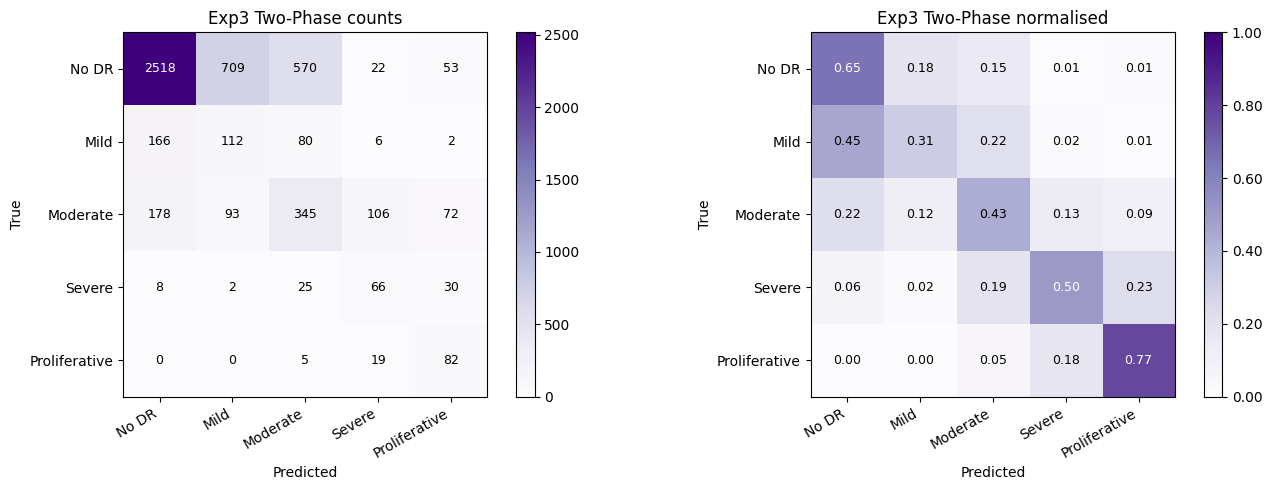

Exp3 QWK: 0.5411


In [6]:
y_true, y_pred = evaluate(model, criterion, optimizer, scaler,
                           test_loader, CKPT_PATH, 'Exp3')
plot_confusion(y_true, y_pred, 'Exp3 Two-Phase', FIG_DIR_E / 'exp3_confusion.png', cmap='Purples')

import json as _json
results = {'qwk': cohen_kappa_score(y_true, y_pred, weights='quadratic'),
           'macro_f1': f1_score(y_true, y_pred, average='macro'),
           'f1_per': f1_score(y_true, y_pred, average=None).tolist(),
           'history_p1': history_p1, 'history_p2': history_p2}
with open(EXP_DIR / 'exp3_results.json', 'w') as f:
    _json.dump(results, f, indent=2)
print(f"Exp3 QWK: {results['qwk']:.4f}")